In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,roc_curve, r2_score
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import MinMaxScaler

In [4]:
df = pd.read_csv('data/depression_data.csv')
df

,Name,Age,Marital Status,Education Level,Number of Children,Smoking Status,Physical Activity Level,Employment Status,Income,Alcohol Consumption,Dietary Habits,Sleep Patterns,History of Mental Illness,History of Substance Abuse,Family History of Depression,Chronic Medical Conditions
0,Christine Barker,31,Married,Bachelor's Degree,2,Non-smoker,Active,Unemployed,26265.67,Moderate,Moderate,Fair,Yes,No,Yes,Yes
1,Jacqueline Lewis,55,Married,High School,1,Non-smoker,Sedentary,Employed,42710.36,High,Unhealthy,Fair,Yes,No,No,Yes
2,Shannon Church,78,Widowed,Master's Degree,1,Non-smoker,Sedentary,Employed,125332.79,Low,Unhealthy,Good,No,No,Yes,No
3,Charles Jordan,58,Divorced,Master's Degree,3,Non-smoker,Moderate,Unemployed,9992.78,Moderate,Moderate,Poor,No,No,No,No
4,Michael Rich,18,Single,High School,0,Non-smoker,Sedentary,Unemployed,8595.08,Low,Moderate,Fair,Yes,No,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413763,Sean Miller,68,Married,Master's Degree,0,Former,Moderate,Employed,109233.43,Low,Healthy,Good,No,No,No,No
413764,Christina Brown,26,Single,Bachelor's Degree,0,Current,Active,Employed,96760.97,Low,Healthy,Poor,Yes,Yes,No,Yes
413765,Matthew Jenkins,57,Married,Bachelor's Degree,0,Non-smoker,Sedentary,Employed,77353.26,Moderate,Moderate,Fair,No,No,Yes,Yes
413766,Gary Faulkner,71,Married,Associate Degree,2,Non-smoker,Sedentary,Unemployed,24557.08,Moderate,Moderate,Poor,No,Yes,No,No


In [5]:
df.columns

Index(['Name', 'Age', 'Marital Status', 'Education Level',
       'Number of Children', 'Smoking Status', 'Physical Activity Level',
       'Employment Status', 'Income', 'Alcohol Consumption', 'Dietary Habits',
       'Sleep Patterns', 'History of Mental Illness',
       'History of Substance Abuse', 'Family History of Depression',
       'Chronic Medical Conditions'],
      dtype='object')

In [6]:
df.describe()

,Age,Number of Children,Income
count,413768.000000,413768.000000,413768.000000
mean,49.000713,1.298972,50661.707971
std,18.158759,1.237054,40624.100565
min,18.000000,0.000000,0.410000
25%,33.000000,0.000000,21001.030000
50%,49.000000,1.000000,37520.135000
75%,65.000000,2.000000,76616.300000
max,80.000000,4.000000,209995.220000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413768 entries, 0 to 413767
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Name                          413768 non-null  object 
 1   Age                           413768 non-null  int64  
 2   Marital Status                413768 non-null  object 
 3   Education Level               413768 non-null  object 
 4   Number of Children            413768 non-null  int64  
 5   Smoking Status                413768 non-null  object 
 6   Physical Activity Level       413768 non-null  object 
 7   Employment Status             413768 non-null  object 
 8   Income                        413768 non-null  float64
 9   Alcohol Consumption           413768 non-null  object 
 10  Dietary Habits                413768 non-null  object 
 11  Sleep Patterns                413768 non-null  object 
 12  History of Mental Illness     413768 non-nul

In [8]:
df.isna().sum()

Name                            0
Age                             0
Marital Status                  0
Education Level                 0
Number of Children              0
Smoking Status                  0
Physical Activity Level         0
Employment Status               0
Income                          0
Alcohol Consumption             0
Dietary Habits                  0
Sleep Patterns                  0
History of Mental Illness       0
History of Substance Abuse      0
Family History of Depression    0
Chronic Medical Conditions      0
dtype: int64

## Getting The Data Ready For The Modeling

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413768 entries, 0 to 413767
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Name                          413768 non-null  object 
 1   Age                           413768 non-null  int64  
 2   Marital Status                413768 non-null  object 
 3   Education Level               413768 non-null  object 
 4   Number of Children            413768 non-null  int64  
 5   Smoking Status                413768 non-null  object 
 6   Physical Activity Level       413768 non-null  object 
 7   Employment Status             413768 non-null  object 
 8   Income                        413768 non-null  float64
 9   Alcohol Consumption           413768 non-null  object 
 10  Dietary Habits                413768 non-null  object 
 11  Sleep Patterns                413768 non-null  object 
 12  History of Mental Illness     413768 non-nul

In [11]:
df.drop(columns='Name',inplace = True)

In [12]:
changes = {'Divorced':0, 'Widowed':1, 'Single':2, 'Married':3}

In [13]:
df['Marital Status'] = df['Marital Status'].map(changes)

In [14]:
changes2 = {"Bachelor's Degree":4, "High School":3, "Associate Degree":2, "Master's Degree":1, "PhD":0}

In [15]:
df['Education Level'] = df['Education Level'].map(changes2)

In [16]:
df['Smoking Status'].value_counts()

Smoking Status
Non-smoker    247416
Former        116184
Current        50168
Name: count, dtype: int64

In [17]:
changes3 = {'Non-smoker':2, 'Former':1, 'Current':0}

In [18]:
df['Smoking Status'] = df['Smoking Status'].map(changes3)
df['Smoking Status'].head()

0    2
1    2
2    2
3    2
4    2
Name: Smoking Status, dtype: int64

In [19]:
df['Physical Activity Level'].value_counts()

Physical Activity Level
Sedentary    176850
Moderate     158013
Active        78905
Name: count, dtype: int64

In [20]:
changes4 = {'Sedentary':2, 'Moderate':1, 'Active':0}

In [21]:
df['Physical Activity Level'] = df['Physical Activity Level'].map(changes4)
df['Physical Activity Level'].value_counts()

Physical Activity Level
2    176850
1    158013
0     78905
Name: count, dtype: int64

In [22]:
df['Employment Status'].value_counts()

Employment Status
Employed      265659
Unemployed    148109
Name: count, dtype: int64

In [23]:
changes5 = {'Employed':1, 'Unemployed':0}

In [24]:
df['Employment Status'] = df['Employment Status'].map(changes5)
df['Employment Status'].value_counts()

Employment Status
1    265659
0    148109
Name: count, dtype: int64

In [25]:
df['Alcohol Consumption'].value_counts()

Alcohol Consumption
Moderate    173440
Low         139250
High        101078
Name: count, dtype: int64

In [26]:
changes6 = {'Moderate':2, 'Low':1, 'High':0}

In [27]:
df['Alcohol Consumption'] = df['Alcohol Consumption'].map(changes6)
df['Alcohol Consumption'].value_counts()

Alcohol Consumption
2    173440
1    139250
0    101078
Name: count, dtype: int64

In [28]:
df['Dietary Habits'].value_counts()

Dietary Habits
Unhealthy    170817
Moderate     170446
Healthy       72505
Name: count, dtype: int64

In [29]:
changes7 = {'Unhealthy':2, 'Moderate':1, 'Healthy':0}

In [30]:
df['Dietary Habits'] = df['Dietary Habits'].map(changes7)
df['Dietary Habits'].value_counts()

Dietary Habits
2    170817
1    170446
0     72505
Name: count, dtype: int64

In [31]:
df['Sleep Patterns'].value_counts()

Sleep Patterns
Fair    196789
Poor    129582
Good     87397
Name: count, dtype: int64

In [32]:
changes8 = {'Fair':2, 'Poor':1, 'Good':0}

In [33]:
df['Sleep Patterns'] = df['Sleep Patterns'].map(changes8)
df['Sleep Patterns'].value_counts()

Sleep Patterns
2    196789
1    129582
0     87397
Name: count, dtype: int64

In [34]:
df['History of Mental Illness'].value_counts()

History of Mental Illness
No     287943
Yes    125825
Name: count, dtype: int64

In [35]:
changes9 = {'No':1, 'Yes':0}

In [36]:
df['History of Mental Illness'] = df['History of Mental Illness'].map(changes9)
df['History of Mental Illness'].value_counts()

History of Mental Illness
1    287943
0    125825
Name: count, dtype: int64

In [37]:
df['History of Substance Abuse'].value_counts()

History of Substance Abuse
No     284880
Yes    128888
Name: count, dtype: int64

In [38]:
changes10 = {'No':1, 'Yes':0}

In [39]:
df['History of Substance Abuse'] = df['History of Substance Abuse'].map(changes10)
df['History of Substance Abuse'].value_counts()

History of Substance Abuse
1    284880
0    128888
Name: count, dtype: int64

In [40]:
df['Family History of Depression'].value_counts()

Family History of Depression
No     302515
Yes    111253
Name: count, dtype: int64

In [41]:
changes11 = {'No':1, 'Yes':0}

In [42]:
df['Family History of Depression'] = df['Family History of Depression'].map(changes11)
df['Family History of Depression'].value_counts()

Family History of Depression
1    302515
0    111253
Name: count, dtype: int64

In [43]:
df['Chronic Medical Conditions'].value_counts()

Chronic Medical Conditions
No     277561
Yes    136207
Name: count, dtype: int64

In [44]:
changes12 = {'No':1, 'Yes':0}

In [45]:
df['Chronic Medical Conditions'] = df['Chronic Medical Conditions'].map(changes12)
df['Chronic Medical Conditions'].value_counts()

Chronic Medical Conditions
1    277561
0    136207
Name: count, dtype: int64

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413768 entries, 0 to 413767
Data columns (total 15 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Age                           413768 non-null  int64  
 1   Marital Status                413768 non-null  int64  
 2   Education Level               413768 non-null  int64  
 3   Number of Children            413768 non-null  int64  
 4   Smoking Status                413768 non-null  int64  
 5   Physical Activity Level       413768 non-null  int64  
 6   Employment Status             413768 non-null  int64  
 7   Income                        413768 non-null  float64
 8   Alcohol Consumption           413768 non-null  int64  
 9   Dietary Habits                413768 non-null  int64  
 10  Sleep Patterns                413768 non-null  int64  
 11  History of Mental Illness     413768 non-null  int64  
 12  History of Substance Abuse    413768 non-nul

## Correlation

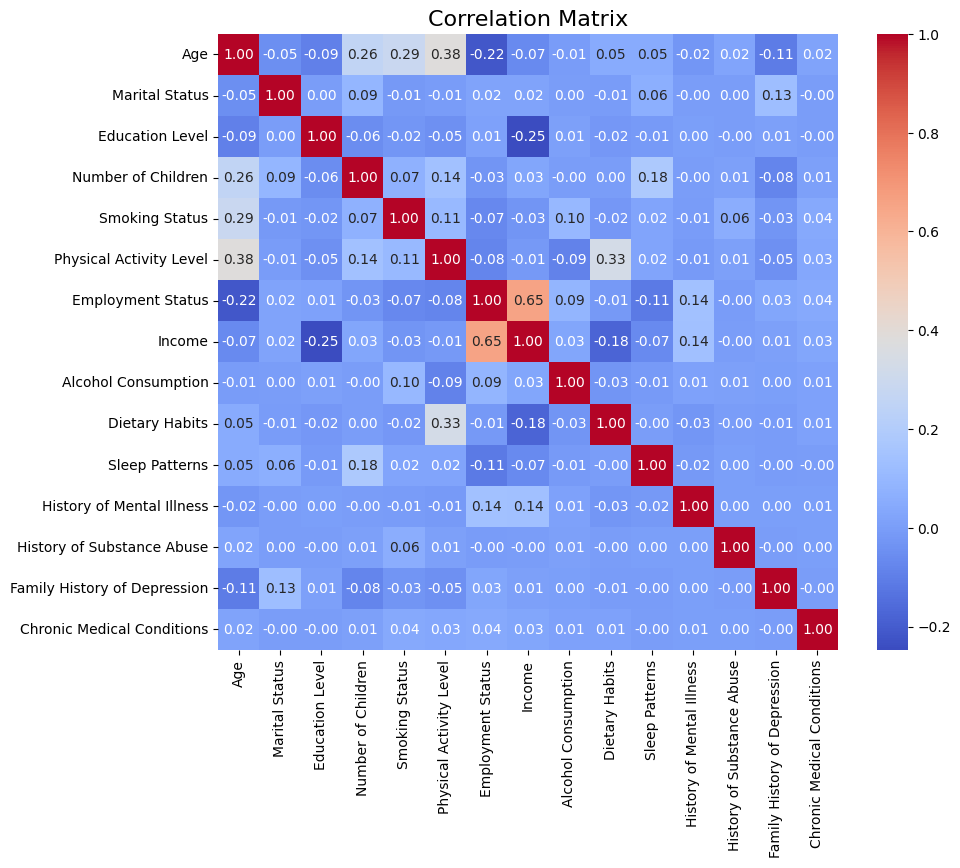

In [47]:
correlation_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix', fontsize=16)
plt.show()

In [50]:
threshold = 0.01
correlation = df.corr()
high_corr_features = correlation.index[abs(correlation['Chronic Medical Conditions']) > threshold].tolist()
high_corr_features.remove('Chronic Medical Conditions')
print('Selected features based on corrolation with target:')
print(high_corr_features)
X_selected = df[high_corr_features]
y = df['Chronic Medical Conditions']

Selected features based on corrolation with target:
['Age', 'Smoking Status', 'Physical Activity Level', 'Employment Status', 'Income', 'Alcohol Consumption', 'Dietary Habits']


## Logistic Regression

In [51]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X_selected)

In [52]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.1, shuffle = True, random_state=42)

In [53]:
model = LogisticRegression() 

In [54]:
X_train.shape

(372391, 7)

In [55]:
model.fit(X_train, Y_train)

LogisticRegression()

In [56]:
model.score(X_train, Y_train)

0.6709560649962002

In [57]:
y_pred = model.predict(X_test)

In [58]:
print(accuracy_score(y_pred, Y_test))

0.6695265485656282


In [59]:
# R2 Score

print("R2 score : ", r2_score(y_pred, Y_test))
print(model.score(X_test, Y_test))


R2 score :  0.0
0.6695265485656282


## KNN

In [60]:
k = 3
knn = KNeighborsClassifier(n_neighbors=k)

In [61]:
knn.fit(X_train, Y_train)

KNeighborsClassifier(n_neighbors=3)

In [62]:
y_pred_knn = knn.predict(X_test)

In [63]:
accuracy = accuracy_score(Y_test, y_pred_knn)
print(accuracy)

0.5862919012978225


In [65]:
AUC = roc_auc_score(Y_test, y_pred_knn)
print("AUC-ROC : ", AUC)

AUC-ROC :  0.5034469593373972


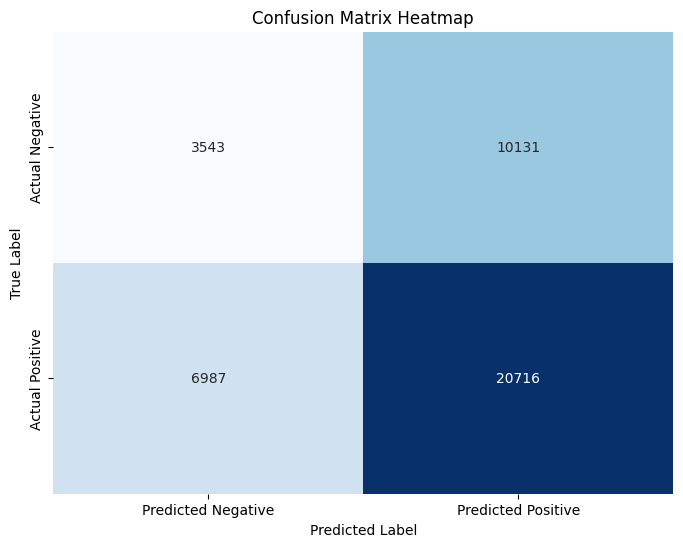

In [66]:
conf_matrix3 =confusion_matrix(Y_test, y_pred_knn)


plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix3, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted Negative", "Predicted Positive"],
            yticklabels=["Actual Negative", "Actual Positive"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix Heatmap")
plt.show()

## Random Forest

In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Normalisation des données
scaler = MinMaxScaler()
X = scaler.fit_transform(X_selected)

# Séparation des données
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

# Création et entraînement du modèle Random Forest
model = RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42)
model.fit(X_train, Y_train)

# Score d'entraînement
train_score = model.score(X_train, Y_train)
print("Score d'entraînement:", train_score)

# Prédiction et évaluation
y_pred = model.predict(X_test)
test_accuracy = accuracy_score(Y_test, y_pred)
print("Accuracy sur test:", test_accuracy)

# AUROC
AUC = roc_auc_score(Y_test, y_pred)
print("AUC-ROC : ", AUC)



Score d'entraînement: 0.7972502673602929
Accuracy sur test: 0.6463615051840395
AUC-ROC :  0.5079568447521269


## Decision tree

In [68]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Normalisation des données
scaler = MinMaxScaler()
X = scaler.fit_transform(X_selected)

# Séparation des données
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

# Création et entraînement du modèle Decision Tree
model = DecisionTreeClassifier(criterion="gini", max_depth=100, random_state=42)
model.fit(X_train, Y_train)

# Score d'entraînement
train_score = model.score(X_train, Y_train)
print("Score d'entraînement:", train_score)

# Prédiction et évaluation
y_pred = model.predict(X_test)
test_accuracy = accuracy_score(Y_test, y_pred)
print("Accuracy sur test:", test_accuracy)

# AUROC
AUC = roc_auc_score(Y_test, y_pred)
print("AUC-ROC : ", AUC)


Score d'entraînement: 1.0
Accuracy sur test: 0.5557193609976557
AUC-ROC :  0.5012916381240664


### Deep learning

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Normalisation
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_selected)

# Séparation en train/test
X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, y, test_size=0.1, shuffle=True, random_state=42)

# Création du modèle
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),  # Couche d'entrée
    keras.layers.Dropout(0.3),
    keras.layers.Dense(128, activation='relu'),  
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation='relu'),  
    keras.layers.Dense(1, activation='sigmoid')  # Activation sigmoïde pour classification binaire
])

# Compilation du modèle
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Entraînement
history = model.fit(X_train, Y_train, epochs=50, batch_size=32, validation_data=(X_test, Y_test), callbacks=[
    keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
])

# Évaluation
test_loss, test_acc = model.evaluate(X_test, Y_test)
print(f"Test Accuracy: {test_acc:.4f}")

# AUROC
y_pred = model.predict(X_test)
AUC = roc_auc_score(Y_test, y_pred)
print("AUC-ROC : ", AUC)


Epoch 1/50
11638/11638 ━━━━━━━━━━━━━━━━━━━━ 26s 2ms/step - accuracy: 0.6711 - loss: 0.6323 - val_accuracy: 0.6695 - val_loss: 0.6309
Epoch 2/50
11638/11638 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.6712 - loss: 0.6299 - val_accuracy: 0.6695 - val_loss: 0.6307
Epoch 3/50
11638/11638 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 0.6707 - loss: 0.6298 - val_accuracy: 0.6695 - val_loss: 0.6307
Epoch 4/50
11638/11638 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 0.6723 - loss: 0.6286 - val_accuracy: 0.6695 - val_loss: 0.6308
Epoch 5/50
11638/11638 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.6704 - loss: 0.6297 - val_accuracy: 0.6695 - val_loss: 0.6306
Epoch 6/50
11638/11638 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.6711 - loss: 0.6294 - val_accuracy: 0.6695 - val_loss: 0.6311
Epoch 7/50
11638/11638 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 0.6709 - loss: 0.6295 - val_accuracy: 0.6695 - val_loss: 0.6306
Epoch 8/50
11638/11638 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 

In [70]:
print(changes2)

{"Bachelor's Degree": 4, 'High School': 3, 'Associate Degree': 2, "Master's Degree": 1, 'PhD': 0}


In [71]:
print(df['Education Level'].value_counts())

Education Level
4    124329
3    118927
2     79999
1     73768
0     16745
Name: count, dtype: int64


In [72]:
# Exemple avec "Education Level"
pd.crosstab(df["Education Level"], df["Chronic Medical Conditions"], normalize="index") * 100


Chronic Medical Conditions,0,1
Education Level,,
0,32.863541,67.136459
1,32.703882,67.296118
2,33.009163,66.990837
3,33.123681,66.876319
4,32.799266,67.200734


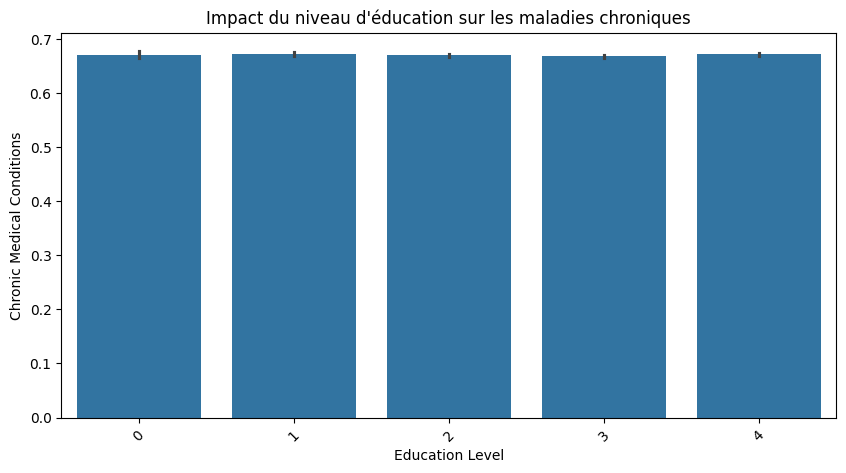

Cette variable n’a pas d’impact. En effet, le taux de maladies chroniques est similaire pour tous les niveaux d’éducation.


In [73]:
plt.figure(figsize=(10,5))
sns.barplot(x="Education Level", y="Chronic Medical Conditions", data=df)
plt.xticks(rotation=45)  # Pour mieux voir les labels
plt.title("Impact du niveau d'éducation sur les maladies chroniques")
plt.show()

print("Cette variable n’a pas d’impact. En effet, le taux de maladies chroniques est similaire pour tous les niveaux d’éducation.")


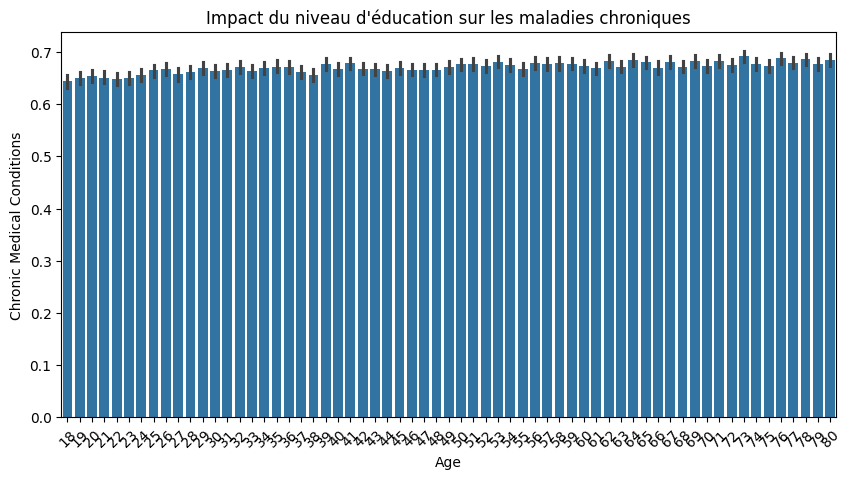

In [74]:
plt.figure(figsize=(10,5))
sns.barplot(x="Age", y="Chronic Medical Conditions", data=df)
plt.xticks(rotation=45)  # Pour mieux voir les labels
plt.title("Impact du niveau d'éducation sur les maladies chroniques")
plt.show()

In [75]:
plt.figure(figsize=(10,5))
sns.barplot(x="Income", y="Chronic Medical Conditions", data=df)
plt.xticks(rotation=45)  # Pour mieux voir les labels
plt.title("Impact du niveau d'éducation sur les maladies chroniques")
plt.show()

KeyboardInterrupt: 

: 

: 

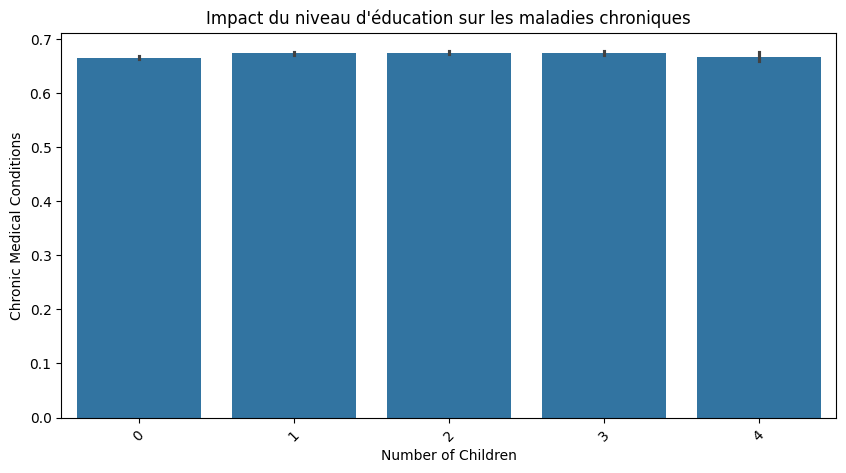

In [91]:
plt.figure(figsize=(10,5))
sns.barplot(x="Number of Children", y="Chronic Medical Conditions", data=df)
plt.xticks(rotation=45)  # Pour mieux voir les labels
plt.title("Impact du niveau d'éducation sur les maladies chroniques")
plt.show()

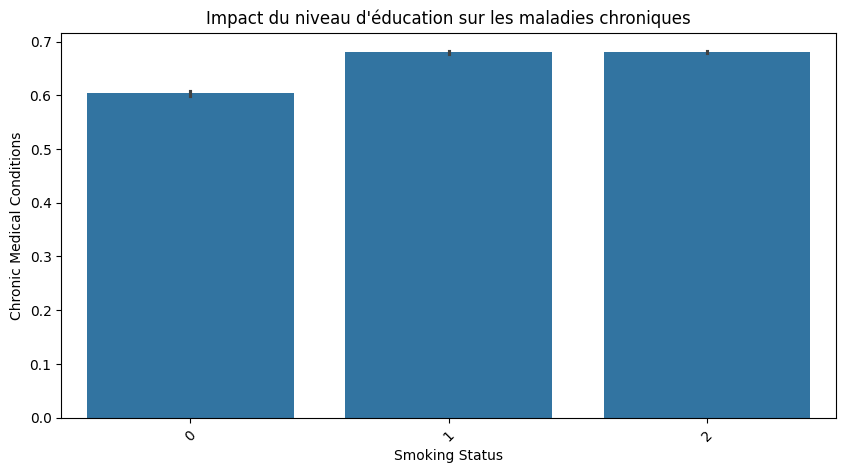

In [92]:
plt.figure(figsize=(10,5))
sns.barplot(x="Smoking Status", y="Chronic Medical Conditions", data=df)
plt.xticks(rotation=45)  # Pour mieux voir les labels
plt.title("Impact du niveau d'éducation sur les maladies chroniques")
plt.show()

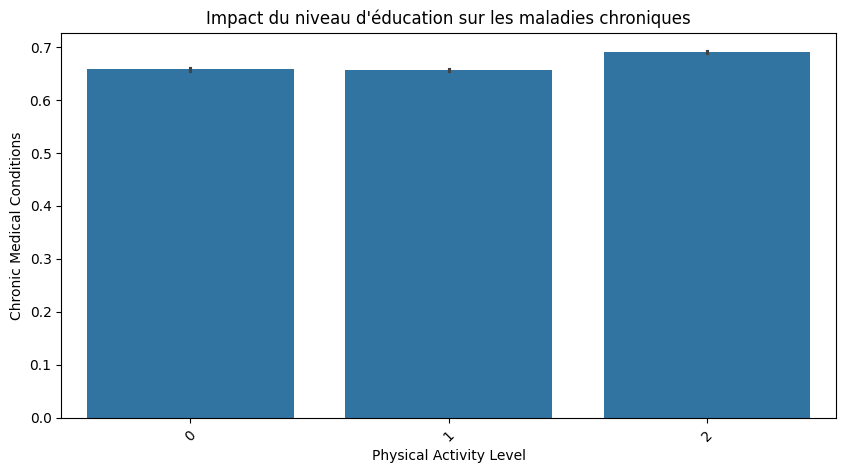

In [93]:
plt.figure(figsize=(10,5))
sns.barplot(x="Physical Activity Level", y="Chronic Medical Conditions", data=df)
plt.xticks(rotation=45)  # Pour mieux voir les labels
plt.title("Impact du niveau d'éducation sur les maladies chroniques")
plt.show()

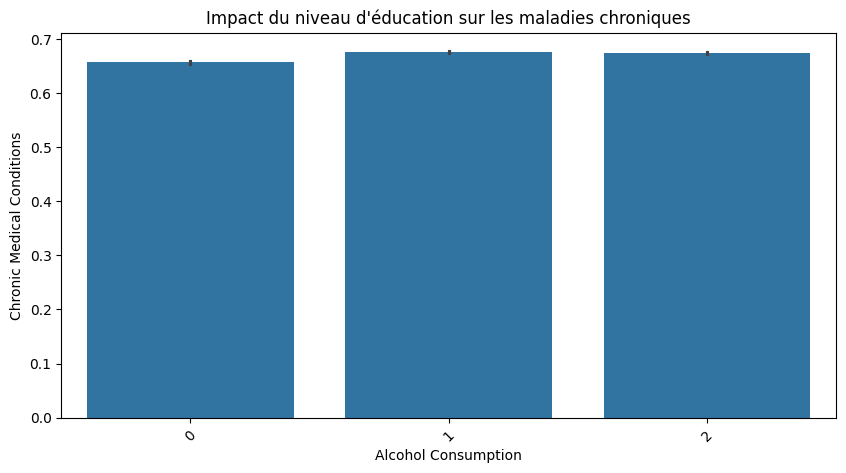

In [94]:
plt.figure(figsize=(10,5))
sns.barplot(x="Alcohol Consumption", y="Chronic Medical Conditions", data=df)
plt.xticks(rotation=45)  # Pour mieux voir les labels
plt.title("Impact du niveau d'éducation sur les maladies chroniques")
plt.show()

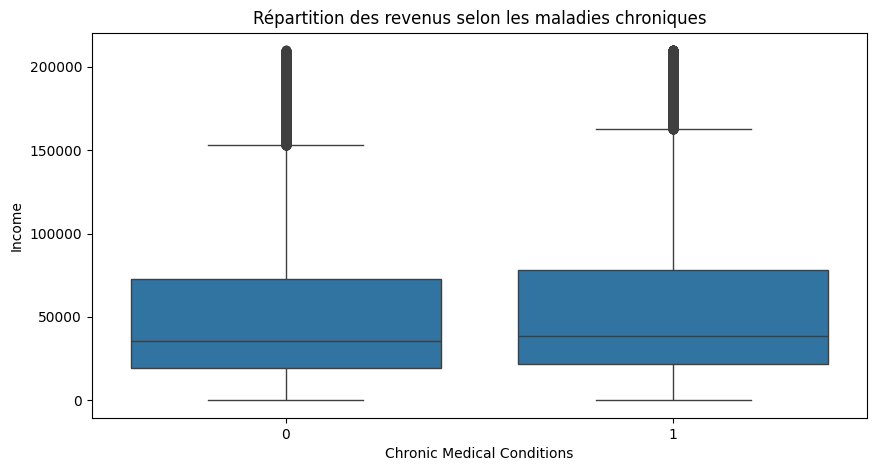

elles sont presque identiques, alors le revenu n’a pas d’impact.


In [96]:
plt.figure(figsize=(10,5))
sns.boxplot(x="Chronic Medical Conditions", y="Income", data=df)
plt.title("Répartition des revenus selon les maladies chroniques")
plt.show()

print("elles sont presque identiques, alors le revenu n’a pas d’impact.")


In [98]:
from causallearn.search.ScoreBased.DAG_GNN import DAG_GNN

# Charger tes données
df = pd.read_csv("data/depression_data.csv")

# Appliquer DAG-GNN
model = DAG_GNN()
dag = model.fit(df)

# Affichage du graphe
plt.figure(figsize=(10, 6))
nx.draw_networkx(dag, with_labels=True, node_size=3000, node_color="lightblue", edge_color="gray")
plt.title("DAG appris avec DAG-GNN")
plt.show()


ModuleNotFoundError: No module named 'causallearn'